# Estimating Peat deformation with Non-linear Least Squares

## Recap of Model 2 (from last week)

We tried to build a better model using the weather file `weather.csv` and link it to our observations. 
We came up with a new model that introduced three terms **1. offset $d_0$**, **2. Irreversible subsidence: $x_I\, D(t)$**  and **3. Reversible movement: $k\, S_\tau(t)$** : 

$$
d(t) = \underbrace{d_0}_{\text{offset}} \;+\; \underbrace{x_I\, D(t)}_{\text{irreversible}} \;+\; \underbrace{k\, S_\tau(t)}_{\text{reversible}} .
$$



For the second process we introduced the **water surplus** $S_\tau$ with a `leaky bucket` function:
$$
S_i = a\, S_{i-1} + (P_i - E_i), \qquad a = e^{-1/\tau}, \qquad S_{-1} = 0,
$$

As you can see this function, $S_\tau$, introduces a memory term $a = e^{-1/\tau}$, where $\tau > 0$ is the memory timescale in days. Last week we fixed $\tau$ to 10 days, but what if we don't know $\tau$ and we want to estimate $\tau$ as an extra unknown parameter? Our unknown parameters that we want to estimate are now: 


| Parameter | Unit | Meaning |
|---|---|---|
| $d_0$ | mm | offset |
| $x_I$ | mm per dry day | **irreversible** subsidence (oxidation), only on dry days|
| $k$ | – | **reversible** response to the water surplus (swelling and shrinking); we expect $k > 0$ |
| $\tau$ | days | **memory** of the soil in the water surplus ($\tau > 0$)|


<!-- $$
d(t) = \underbrace{d_0}_{\text{offset}} \;+\; \underbrace{x_I\, D(t)}_{\text{irreversible}} \;+\; \underbrace{k\, (e^{-1/\tau}S_{i-1} + (P_i - E_i))}_{\text{reversible}} .
$$ -->



$D(t)$ is the dry days counter and can be found in the weather file under `DryDays[days]`, same as *precipitation* `Precipitation[mm]` and *evapotranspiration* `Evapotranspiration[mm]`.



In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2
from ipywidgets import interact, FloatSlider

np.set_printoptions(precision=3)

## Part 1: Load the data like last week and reuse some of last week's functions






### A reminder of the data

We have two independent measurement techniques that observe the **same parcel**:

| | InSAR | Extensometer |
|---|---|---|
| What is measured | Average height change of the **whole parcel** (radar satellite) | Height change at **one point** in the parcel (instrument in a borehole) |
| Sampling | every 6 days (some epochs missing due to lack of coherence) | daily |
| Precision | $\sigma_{\text{InSAR}} = 3$ mm | $\sigma_{\text{ext}} = 8$ mm |

The file contains one row for **every day** from 1 January 2020 to 31 December 2023. The weather starts one year *before* the first observation (1 January 2019).

And we have data from `weather.csv`:

| Column | Unit | Meaning |
|---|---|---|
| `Dates` | – | calendar date |
| `Day` | days | number of days since 1 January 2019 (day 0) |
| `Precipitation[mm]` | mm/day | precipitation $P$: water that comes **in** (rain) |
| `Evapotranspiration[mm]` | mm/day | evapotranspiration $E$: water that goes **out** (evaporation from the soil + transpiration by the grass) |
| `Dry[-]` | – | 1 if the day is **dry**, 0 if it is wet |
| `DryDays[days]` | days | $D(t)$: the **number of dry days** counted from the start of the file up to and including that day |

The difference $P - E$ [mm/day] is the **net water input** of the parcel. Positive means the parcel gets wetter that day; negative means it dries out.



Download and read the data (like last week)

In [15]:
import os
from urllib.request import urlretrieve

def findfile(fname):
    if not os.path.isfile(fname):
        print(f'Downloading {fname}...')
        urlretrieve('https://github.com/TUDelft-MUDE/source-files/raw/main/file/GA1.8/'+fname, fname)

findfile('insar_observations.csv')
findfile('extensometer_observations.csv')
findfile('weather.csv')

In [16]:
insar = pd.read_csv('insar_observations.csv')
ext = pd.read_csv('extensometer_observations.csv')
weather = pd.read_csv('weather.csv')

dates_insar = pd.to_datetime(insar['Dates'])
day_insar = insar['Day'].to_numpy()
y_insar = insar['Observations[m]'].to_numpy() * 1000      # mm

dates_ext = pd.to_datetime(ext['Dates'])
day_ext = ext['Day'].to_numpy()
y_ext = ext['Observations[m]'].to_numpy() * 1000          # mm

dates_weather = pd.to_datetime(weather['Dates'])
P = weather['Precipitation[mm]'].to_numpy()                # mm/day
E = weather['Evapotranspiration[mm]'].to_numpy()           # mm/day

sigma_insar = 3   # mm
sigma_ext = 8     # mm

Here are some functions from last week that you can use again:

In [17]:
def BLUE(A, y, Sigma_Y):
    '''Best Linear Unbiased Estimator.

    Input:  A, y , Sigma_Y
    Output: xhat , Sigma_X 
    '''
    inv_Sigma_Y = np.linalg.inv(Sigma_Y)
    Sigma_X = np.linalg.inv(A.T @ inv_Sigma_Y @ A)
    xhat = Sigma_X @ A.T @ inv_Sigma_Y @ y
    return xhat, Sigma_X

def water_surplus(P, E, tau):
    '''Leaky-bucket water surplus S [mm] for every day of the weather record.'''
    a = np.exp(-1 / tau)
    S = np.zeros(len(P))
    S_previous = 0.0
    for i in range(len(P)):
        S[i] = a * S_previous + (P[i] - E[i])
        S_previous = S[i]
    return S

def get_results(A, y, Sigma_Y, xhat, Sigma_Xhat):
    yhat = A @ xhat
    ehat = y - yhat
    Sigma_Yhat = A @ Sigma_Xhat @ A.T
    Sigma_ehat = Sigma_Y - Sigma_Yhat
    std_yhat = np.sqrt(np.diag(Sigma_Yhat))
    std_ehat = np.sqrt(np.diag(Sigma_ehat))
    return yhat, ehat, std_yhat, std_ehat


def plot_results(name, dates, y, yhat, ehat, std_yhat, std_ehat, sigma, alpha):
    '''Plot observations + fitted model, residuals and a histogram of the normalized residuals.'''
    k98 = norm.ppf(1-0.5*alpha) 
    CI_e = k98 * std_ehat
    CI_yhat = k98 * std_yhat
    fig = plt.figure(figsize=(14, 8))
    ax1 = plt.subplot2grid((2, 3), (0, 0), colspan=3)
    ax2 = plt.subplot2grid((2, 3), (1, 0), colspan=2)
    ax3 = plt.subplot2grid((2, 3), (1, 2))

    ax1.plot(dates, y, '.', color='k', ms=3, label='observations')
    ax1.plot(dates, yhat, color='tab:red', label='fitted model')
    ax1.fill_between(dates, yhat - CI_yhat, yhat + CI_yhat,
                     color='tab:red', alpha=0.3, label=f'CI yhat {100 * (1 - alpha):.0f}%')

    ax1.set_xlim(dates.iloc[0], dates.iloc[-1])
    ax1.set_ylabel('displacement [mm]')
    ax1.set_title(f'{name}: observations and fitted model')
    ax1.legend(loc='lower left')


    ax2.plot(dates, ehat, '.', color='k', ms=3)
    ax2.fill_between(dates, -CI_e, CI_e, color='tab:red', alpha=0.2,
                     label=f'CI ehat {100 * (1 - alpha):.0f}%')

    ax2.set_xlim(dates.iloc[0], dates.iloc[-1])
    ax2.set_ylabel('residual [mm]')
    ax2.set_title('residuals')
    ax2.legend(loc='lower left')

    ax3.hist(ehat / std_ehat, bins=15, density=True, color='lightgrey', edgecolor='k')
    xx = np.linspace(-4, 4, 200)
    ax3.plot(xx, norm.pdf(xx), color='tab:red', label='N(0,1)')
    ax3.set_xlabel('residual / sigma [-]')
    ax3.set_title('normalized residuals')
    ax3.legend()
    plt.tight_layout()
    plt.show()

    print(f'{name}: mean residual = {ehat.mean():.2f} mm, std residual = {ehat.std():.2f} mm '
          f'(sigma = {sigma} mm)')


> **Task 1.1:**
>
> Complete the function `forward_model` $q(x)$ at the observation days (the column `Day`).
>


In [21]:
D = weather['DryDays[days]'].to_numpy()

def forward_model(x, day):
    '''Forward model q(x): modelled displacement [mm] on the days in `day`.

    Input:  x = [d0, x_I, k, tau], day (array of day numbers)
    Output: modelled displacement [mm]
    '''
    d0, x_I, k, tau = x
    S = water_surplus(P, E, tau)
    return d0 + x_I*D[day] + k*S[day]


> **Task 1.2:**
>
> Choose initial values $x_{[0]} = [d_0,\ x_I,\ k,\ \tau]$ for the Gauss-Newton iteration. Use the interactive plot below to justify your choice. You can:
> 1. start from **last week's estimates** (where $\tau$ was fixed to 10 days) and only adjust $\tau$, or
> 2. reason about what each term does: $d_0$ shifts the whole curve up/down, $x_I$ sets the long-term downward trend, $k$ scales the seasonal swelling/shrinking, and $\tau$ controls how fast the soil "forgets" rain (small $\tau$: spiky, large $\tau$: smooth and delayed).
>
> You don't need a perfect fit: the goal is to get a good initial guess, Gauss-Newton will do the rest.
>
> *Note: interactive plots only work when you run the notebook locally.*


In [23]:
# Your initial guess
d0_i = 16
xI_i = -0.042
k_i = 0.46
tau_i = 10

def plot_initial_guess(d0, x_I, k, tau):
    x = [d0, x_I, k, tau]
    fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    for a, name, dates, day, y, sigma in [(ax[0], 'InSAR', dates_insar, day_insar, y_insar, sigma_insar),
                                          (ax[1], 'Extensometer', dates_ext, day_ext, y_ext, sigma_ext)]:
        q0 = forward_model(x, day)
        T0 = np.sum((y - q0)**2) / sigma**2
        a.plot(dates, y, '.', color='k', ms=3, label='observations')
        a.plot(dates, q0, color='tab:red', label=r'model with initial values $x_{[0]}$')
        a.set_ylim(y.min() - 3 * sigma, y.max() + 3 * sigma)
        a.set_ylabel('displacement [mm]')
        a.set_title(f'{name}: weighted sum of squared residuals = {T0:.0f}')
        a.legend(loc='lower left')
    plt.tight_layout()
    plt.show()

interact(plot_initial_guess,
         d0=FloatSlider(value=d0_i, min=-20, max=30, step=0.5, description='d0 [mm]', continuous_update=False),
         x_I=FloatSlider(value=xI_i, min=-0.15, max=0, step=0.005, readout_format='.3f',
                         description='x_I [mm/day]', continuous_update=False),
         k=FloatSlider(value=k_i, min=0, max=1.5, step=0.01, description='k [-]', continuous_update=False),
         tau=FloatSlider(value=tau_i, min=1, max=100, step=1, description='τ [days]', continuous_update=False));


interactive(children=(FloatSlider(value=16.0, continuous_update=False, description='d0 [mm]', max=30.0, min=-2…

## Part 2: The Jacobian matrix 

Gauss-Newton needs the Jacobian matrix $J$, which contains the partial derivatives of the model with respect to each of the unknowns, evaluated at the current estimate:

$$
J = \left[\frac{\partial q}{\partial d_0},\ \frac{\partial q}{\partial x_I},\ \frac{\partial q}{\partial k},\ \frac{\partial q}{\partial \tau}\right].
$$

> **Task 2.1:**
>
> Derive the partial derivatives of the forward model $q(x)$ with respect to each of the four unknowns: $\dfrac{\partial q}{\partial d_0}$, $\dfrac{\partial q}{\partial x_I}$, $\dfrac{\partial q}{\partial k}$ and $\dfrac{\partial q}{\partial \tau}$.
>
> *Hint:* for $\dfrac{\partial q}{\partial \tau}$, use the product rule.
> Because $S_\tau$ is recursive, your answer may contain $\dfrac{\partial S_{i-1}}{\partial \tau}$, with the initial condition $\dfrac{\partial S_{-1}}{\partial \tau}=0$ (so we start computing $\dfrac{\partial S}{\partial \tau}$ day by day from zero).
>
> *Note down your derivation with pen and paper.*


> **Task 2.2:**
>
> Complete the functions below to compute the Jacobian matrix $J$, using the partial derivatives you derived in Task 2.1.
> 1. `water_surplus_and_derivative` computes $S_\tau$ and $\dfrac{\partial S_\tau}{\partial \tau}$ day by day.
> 2. `jacobian` returns $J$ for the observation days, evaluated at $x = [d_0,\ x_I,\ k,\ \tau]$.
>
> Run the check cell to see if your Jacobian is correct. Then print the first 5 rows of $J$ for the InSAR data, using your initial values `x0`.


In [47]:
def water_surplus_and_derivative(P, E, tau):
    '''Leaky-bucket water surplus S [mm] and its derivative dS/dtau [mm/day].'''
    a = np.exp(-1/tau)
    S = np.zeros(len(P))
    dS = np.zeros(len(P))
    S_previous, dS_previous = np.zeros((2,))
    for i in range(len(P)):
        S[i] = a * S_previous + (P[i] - E[i])

        # calc derivative
        dS[i] = S_previous * (a/tau**2) + a * dS_previous

        S_previous = S[i]
        dS_previous = dS[i]
    return S, dS
# def water_surplus_and_derivative(P, E, tau):
#     '''Leaky-bucket water surplus S [mm] and its derivative dS/dtau [mm/day].'''
#     a = np.exp(-1 / tau)
#     S = np.zeros(len(P))
#     dS = np.zeros(len(P))
#     S_previous, dS_previous = 0, 0
#     for i in range(len(P)):
#         S[i] = a * S_previous + (P[i] - E[i])
#         dS[i] = a * dS_previous + (a / tau**2) * S_previous 
#         S_previous, dS_previous = S[i], dS[i]
#     return S, dS

def jacobian(x, day):
    '''Jacobian matrix of the model at the days `day`, evaluated at x = [d0, x_I, k, tau].'''
    d0, x_I, k, tau = x
    S, dS = water_surplus_and_derivative(P, E, tau)

    size = np.shape(day)[0]
    dd0 = np.ones((size,))
    dxI = D[day]
    dk = S[day]
    dq = k * dS[day]
    J = np.column_stack((dd0, dxI, dk, dq))
    return J





Run the cell below to check if your Jacobian matrix is correct.

In [48]:
# Check Jacobian function
x_check = [1.0, -0.05, 0.5, 20.0]
day_check = np.array([365, 500, 700])

J_check = jacobian(x_check, day_check)

J_expected = np.array([
    [1.0, 145.0, 46.869,  1.253],
    [1.0, 180.0,  3.887, -0.046],
    [1.0, 284.0, 68.827,  0.968]
])

if np.allclose(J_check, J_expected, atol=1e-3):
    print("Jacobian matches the expected output!")
else:
    print("Jacobian does NOT match the expected output.")
    print("Computed J:\n", J_check)
    print("Expected J:\n", J_expected)


Jacobian matches the expected output!


In [50]:
# d0_i = 16
# xI_i = -0.042
# k_i = 0.46
# tau_i = 10

x0 = [d0_i, xI_i, k_i, tau_i]


J = jacobian(x0, day_insar)

print('The first 5 rows of the Jacobian matrix (InSAR) are:')
print(J[0:5, :])

The first 5 rows of the Jacobian matrix (InSAR) are:
[[  1.    145.     19.903   1.294]
 [  1.    145.     19.086   1.152]
 [  1.    145.     18.855   0.962]
 [  1.    145.     17.238   0.915]
 [  1.    145.     22.777   0.948]]


## Part 3: Gauss-Newton iteration algorithm


> **Task 3.1:**
>
> Set up the stochastic model: the covariance matrices `Sigma_Y_insar` and `Sigma_Y_ext`, like last week. Remember that the observations are normally distributed and independent, with $\sigma_{\text{InSAR}} = 3$ mm and $\sigma_{\text{ext}} = 8$ mm.


In [51]:
day_0 = 365
year = 365.25
t_insar = (day_insar-day_0)/year
t_ext = (day_ext-day_0)/year

Sigma_Y_insar = np.diag(np.ones(np.shape(t_insar)[0])*sigma_insar**2)
Sigma_Y_ext = np.diag(np.ones(np.shape(t_ext)[0])*sigma_ext**2)

print('shape of Sigma_Y_insar:', Sigma_Y_insar.shape)
print('shape of Sigma_Y_ext:', Sigma_Y_ext.shape)


shape of Sigma_Y_insar: (145, 145)
shape of Sigma_Y_ext: (1461, 1461)


> **Task 3.2:**
>
> 1. Set up a Gauss-Newton iteration algorithm by completing the function `gauss_newton`. The estimate of every iteration is stored in `xhat_i`, so that we can study the convergence.
> 2. Run the Gauss-Newton function to obtain `xhat, Sigma_Xhat, xhat_i, niter, J_final`.

In [52]:
def gauss_newton(x0, day, y_obs, Sigma_Y, max_iter=50):
    '''Use Gauss-Newton iteration to find the non-linear parameters.'''

    xnrm = 1000                      # initialize stop criterion

    xhat_i = np.zeros((max_iter, 4))
    xhat_i[0, :] = x0

    iter_ind = 0

    while xnrm >= 1e-12 and iter_ind < max_iter - 1:

        # computed displacement based on the current estimate
        y_i = forward_model(xhat_i[iter_ind, :], day)

        dy = y_obs - y_i
        J = jacobian(x0, day)

        d_xhat, Sigma_Xhat = BLUE(J, y_obs, Sigma_Y)
        # Hint: re-use your function BLUE

        xhat_i[iter_ind + 1, :] = xhat_i[iter_ind, :] + d_xhat
        
        inv_Sigma_Y = np.linalg.inv(Sigma_Y)
        xnrm = d_xhat.T @ J.T @ inv_Sigma_Y @ J @ d_xhat#Delta_x_hat_i.T @ N_i @ Delta_x_hat_i

        # Update the iteration number
        iter_ind += 1

        if iter_ind == max_iter - 1:
            print('Number of iterations too large, check initial values.')

    xhat = xhat_i[iter_ind, :]
    xhat_i = xhat_i[0:iter_ind + 1, :]
    return xhat, Sigma_Xhat, xhat_i, iter_ind, J


> **Task 3.3:**
>
> Apply Gauss-Newton to both datasets, starting from your initial values `x0`. Print the estimates and the number of iterations, and use the (given) function `plot_convergence` to show how the parameters change during the iterations.



In [53]:
labels = ['d0', 'x_I', 'k', 'tau']
units = ['mm', 'mm/dry day', '-', 'days']


def plot_convergence(name, x_history):
    '''Plot the value of each parameter versus the iteration number.'''
    fig, ax = plt.subplots(1, len(labels), figsize=(14, 3))
    for j in range(len(labels)):
        ax[j].plot(x_history[:, j], 'o-')
        ax[j].axhline(x_history[-1, j], color='grey', ls='--', lw=1)    # final estimate
        ax[j].set_title(labels[j])
        ax[j].set_xlabel('iteration')
        ax[j].set_ylabel(f'{labels[j]} [{units[j]}]')
    fig.suptitle(f'Convergence: {name}')
    plt.tight_layout()
    plt.show()

Number of iterations too large, check initial values.
Number of iterations too large, check initial values.


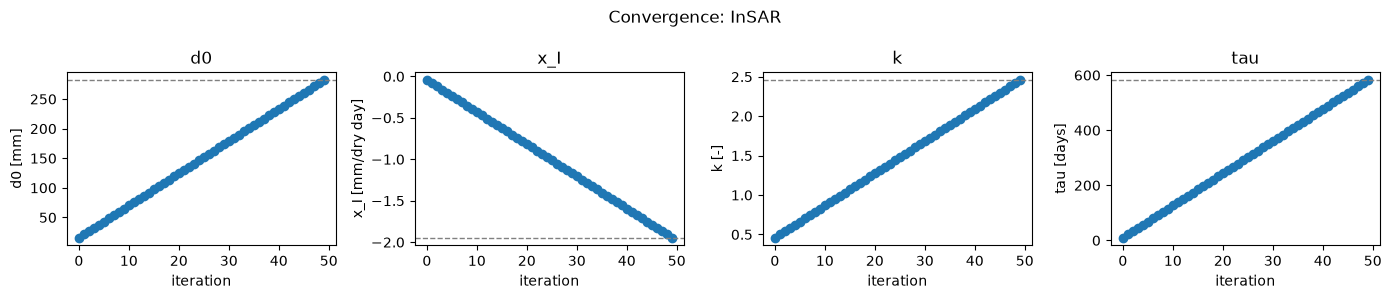

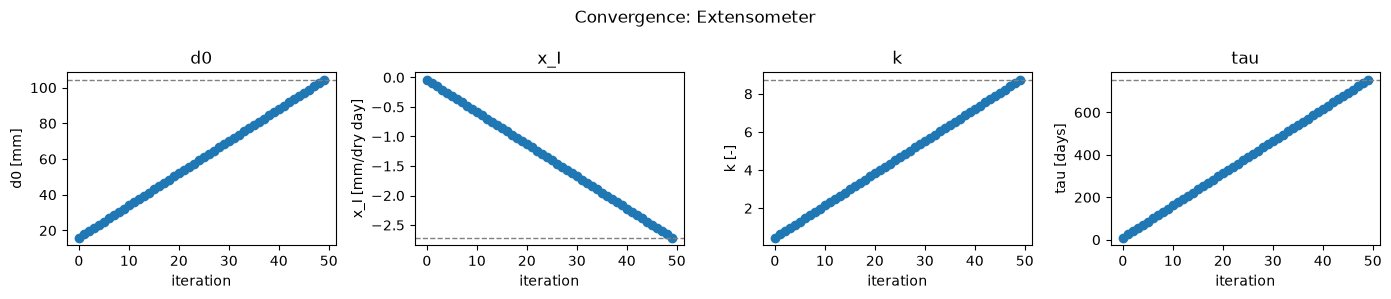

InSAR: converged after 49 iterations: d0 = 282.3321 ± 0.7320 mm, x_I = -1.9448 ± 0.0016 mm/dry day, k = 2.4602 ± 0.0249 -, tau = 582.7948 ± 0.6362 days
Extensometer: converged after 49 iterations: d0 = 104.3448 ± 0.5992 mm, x_I = -2.7117 ± 0.0014 mm/dry day, k = 8.7322 ± 0.0241 -, tau = 753.3470 ± 0.6081 days


In [55]:
xhat_insar, Sigma_Xhat_insar, xhat_i_insar, niter_insar, J_final_insar = gauss_newton(x0, day_insar, y_insar, Sigma_Y_insar)
xhat_ext, Sigma_Xhat_ext, xhat_i_ext, niter_ext, J_final_ext = gauss_newton(x0, day_ext, y_ext, Sigma_Y_ext)

plot_convergence('InSAR', xhat_i_insar)
plot_convergence('Extensometer', xhat_i_ext)

print(f'InSAR: converged after {niter_insar} iterations: ' + ', '.join(f'{labels[j]} = {xhat_insar[j]:.4f} ± {np.sqrt(Sigma_Xhat_insar[j, j]):.4f} {units[j]}' for j in range(len(labels))))
print(f'Extensometer: converged after {niter_ext} iterations: ' + ', '.join(f'{labels[j]} = {xhat_ext[j]:.4f} ± {np.sqrt(Sigma_Xhat_ext[j, j]):.4f} {units[j]}' for j in range(len(labels))))


### Precision of the estimates

> **Task 3.4:**
>
> What is the quality of the final estimates?
>
> Complete the function `get_results_nonlinear` to compute $\hat{y}$, $\hat{\epsilon}$ and their standard deviations for the non-linear model. Compare it with your function `get_results` from last week: what replaces the design matrix $A$, and how do you compute $\hat{y}$?
>
> Then plot the results for both datasets with `plot_results` (98% confidence level). You can use your old function from last week that we already defined at the beginning of the notebook.


In [ ]:
def get_results_nonlinear(y, day, Sigma_Y, xhat, Sigma_X):
    '''Adjusted observations, residuals and their standard deviations (non-linear model).'''
    J = ### YOUR CODE HERE ###
    yhat = ### YOUR CODE HERE ###
    ehat = ### YOUR CODE HERE ###
    Sigma_Yhat = ### YOUR CODE HERE ###
    Sigma_ehat = ### YOUR CODE HERE ###
    std_yhat = ### YOUR CODE HERE ###
    std_ehat = ### YOUR CODE HERE ###
    return yhat, ehat, std_yhat, std_ehat

yhat_insar, ehat_insar, std_yhat_insar, std_ehat_insar = ### YOUR CODE HERE ###
yhat_ext, ehat_ext, std_yhat_ext, std_ehat_ext = ### YOUR CODE HERE ###

plot_results('InSAR', dates_insar, y_insar, yhat_insar, ehat_insar,
             std_yhat_insar, std_ehat_insar, sigma_insar, alpha=0.02)
plot_results('Extensometer', dates_ext, y_ext, yhat_ext, ehat_ext,
             std_yhat_ext, std_ehat_ext, sigma_ext, alpha=0.02)


## Part 4: Model testing

So far we judged our model by *looking* at the residuals and the histogram. Now we will do this objectively with the **Overall Model Test (OMT)**.

We test this week's non-linear model, with $\tau$ estimated with Gauss-Newton:

$$
d(t) = d_0 + x_I\, D(t) + k\, S_\tau(t), \qquad \text{unknowns: } d_0,\ x_I,\ k,\ \tau
$$


> **Task 4.1:**
>
> Complete the function `overall_model_test`. Calculate the redundancy $r$, the test statistic $T$ and the critical value $k_\alpha$, using the redundancy $r$ as degrees of freedom.
>


In [ ]:
def overall_model_test(name, ehat, Sigma_Y, J, alpha):
    '''Overall model test'''

    # Redundancy
    r = ### YOUR CODE HERE ###

    # OMT test statistic
    T = ### YOUR CODE HERE ###

    # OMT critical value
    k_alpha = ### YOUR CODE HERE ###

    print(f'{name}: test statistic is {T:.2f}, critical value is {k_alpha:.2f} (r = {r})')
    if ### YOUR CODE HERE ###:
        print('We accept the null hypothesis H0\n')
    else:
        print('We reject the null hypothesis H0\n')
    return T, k_alpha

> **Task 4.2:**
>
> Test this week's model for both datasets with your function `overall_model_test` ($\alpha = 0.05$). What is the null hypothesis? Interpret the results: what do they tell you about the functional model and about the assumed precision of the observations?


In [ ]:
T_insar, k_insar = ### YOUR CODE HERE ###
T_ext, k_ext = ### YOUR CODE HERE ###


> By Isabel Slingerland, Delft University of Technology. CC BY 4.0, more info [on the Credits page of Workbook](https://mude.citg.tudelft.nl/workbook-2026/credits.html).